# 23CSE301 Machine Learning Capstone Project — Review 2
## Track 3: Clustering — Unsupervised Discovery of Accident Patterns
**Course Code:** 23CSE301 — Machine Learning
**Evaluation Scope:** Review 2 — full Clustering track (K-Means + Agglomerative Hierarchical Clustering)
**Dataset:** US Accidents (Updated Dec 2020) — `data/US_Accidents_Dec20_Updated.csv`
**Mandatory metrics:** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index
**Mandatory visuals:** K-Means Elbow curve · Dendrogram · PCA-2D scatter per algorithm · t-SNE (≥ 1 algorithm)

## 1. Problem Definition — Supervised vs. Unsupervised
**Question.** *Do accident records fall into natural groups — "kinds" of accident circumstances — when we describe each accident only by **where** it happened, **when** it happened, the **weather** at that moment and the **road infrastructure** nearby?*

| | Classification (Review 1/2) | Clustering (this notebook) |
|---|---|---|
| Learning type | Supervised | **Unsupervised** |
| Uses a target label while fitting? | Yes — `Severity` | **No** — the algorithm never sees any outcome |
| Output | Predicted class for a new accident | A *group id* for every accident, plus a profile of each group |
| How it is judged | Accuracy / F1 / AUC against known labels | **Internal** validity indices (cohesion vs. separation) computed from the features alone |

**Label policy (enforced in code, see Section 3).** `Severity` and `Distance(mi)` — our two outcome variables — are **never** part of the clustering feature matrix, never used for choosing *k*, never used for sampling and never used for feature learning. They are loaded into a separate table and examined **only after** all models are fitted (Section 11), clearly labelled as *external, post-hoc interpretation*, and kept apart from the three required internal metrics.

In [1]:
import warnings, time, os, json
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100
PALETTE = sns.color_palette('tab10')            # colour-blind-friendly categorical palette (guideline 7.3)
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__, '| seed', SEED)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | seed 42


## 2. Data Loading & Audit

In [2]:
df_raw = pd.read_csv('../data/US_Accidents_Dec20_Updated.csv', low_memory=False)
print(f'Dataset as read: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns | duplicate rows: {df_raw.duplicated().sum()}')
# The supplied CSV is exactly 16 MiB and its final record (A-42768) is cut off mid-row: Start_Lng, every road flag and all weather fields are missing.
# Clustering needs complete location/time/infrastructure fields, so incomplete records are removed (here: exactly one).
incomplete = df_raw[['Start_Lat', 'Start_Lng', 'Start_Time'] + ['Amenity', 'Crossing', 'Junction', 'Traffic_Signal']].isna().any(axis=1)
print('Incomplete (truncated) records removed:', df_raw.loc[incomplete, 'ID'].tolist())
df_raw = df_raw.loc[~incomplete].reset_index(drop=True)
print(f'Records used for clustering: {len(df_raw):,}')
cand = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Start_Time', 'Sunrise_Sunset',
        'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal']
audit = pd.DataFrame({'dtype': df_raw[cand].dtypes.astype(str), 'missing_%': (df_raw[cand].isna().mean() * 100).round(2), 'n_unique': df_raw[cand].nunique()})
audit

Dataset as read: 42,768 rows x 47 columns | duplicate rows: 0
Incomplete (truncated) records removed: ['A-42768']
Records used for clustering: 42,767


,dtype,missing_%,n_unique
Start_Lat,float64,0.00,39614
Start_Lng,float64,0.00,39639
Temperature(F),float64,2.30,563
Humidity(%),float64,2.43,99
Pressure(in),float64,1.96,737
Visibility(mi),float64,2.45,44
Wind_Speed(mph),float64,10.56,67
Start_Time,str,0.00,42541
Sunrise_Sunset,str,0.01,2
Amenity,object,0.00,2


## 3. Feature Selection for Clustering — and Why It Differs from Classification
Clustering relies on **distances between records**, so a feature set that is fine for a tree-based classifier is not automatically fine here. Our rules:

| Group | Included features | Justification |
|---|---|---|
| Geographic | `Start_Lat`, `Start_Lng` | Where accidents happen is the strongest natural structure (urban corridors, regions). `State`/`City`/`Zipcode` are *not* used: they are redundant with coordinates and one-hot encoding hundreds of levels would swamp Euclidean distance. |
| Temporal | `Start_Time` → **cyclic** `hour`, `weekday`, `month` (sin/cos pairs) | Hour 23 and hour 0 are neighbours; raw integers would put them 23 units apart. Cyclic encoding fixes that for distance-based methods (classification used raw integers, which is fine for trees). |
| Environmental | `Temperature(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)`, `Sunrise_Sunset` (→ `Is_Night`) | Conditions at the time of the accident. `Wind_Chill(F)` (41 % missing, near-duplicate of temperature) and `Precipitation(in)` (45 % missing) are dropped. |
| Road infrastructure | `Amenity, Bump, Crossing, Give_Way, Junction, No_Exit, Railway, Roundabout, Station, Stop, Traffic_Calming, Traffic_Signal` — *only those present in ≥ 1 % of records* | A binary flag that is almost always 0 contributes noise, not structure; the prevalence filter is computed from features only. |

**Excluded on purpose:** `Severity`, `Distance(mi)` (outcome labels), `End_Lat`, `End_Lng`, `End_Time` (post-event information, the same leakage policy as Reviews 1/2), `ID`, `Description` (identifier / free text), `Street`, `City`, `Zipcode`, `Airport_Code`, `County` (high cardinality), `Country`, `Turning_Loop` (constant), `Number`, `Wind_Chill(F)`, `Precipitation(in)` (heavy missingness), `Weather_Condition`, `Wind_Direction`, `Timezone`, `Civil/Nautical/Astronomical_Twilight` (categorical / redundant with `Sunrise_Sunset`).

In [3]:
# ---- Build the clustering feature matrix. Outcome labels go to a SEPARATE table (`ref`) that is never passed to any model. ----
ref = df_raw[['Severity', 'Distance(mi)']].copy()                         # external reference only (Section 11)

t = pd.to_datetime(df_raw['Start_Time'], format='mixed')
feat = pd.DataFrame({
    'Start_Lat': df_raw['Start_Lat'], 'Start_Lng': df_raw['Start_Lng'],
    'Temperature(F)': df_raw['Temperature(F)'], 'Humidity(%)': df_raw['Humidity(%)'], 'Pressure(in)': df_raw['Pressure(in)'],
    'Visibility(mi)': df_raw['Visibility(mi)'], 'Wind_Speed(mph)': df_raw['Wind_Speed(mph)'],
    'Hour_sin': np.sin(2 * np.pi * t.dt.hour / 24), 'Hour_cos': np.cos(2 * np.pi * t.dt.hour / 24),
    'Weekday_sin': np.sin(2 * np.pi * t.dt.dayofweek / 7), 'Weekday_cos': np.cos(2 * np.pi * t.dt.dayofweek / 7),
    'Month_sin': np.sin(2 * np.pi * (t.dt.month - 1) / 12), 'Month_cos': np.cos(2 * np.pi * (t.dt.month - 1) / 12),
    'Is_Night': (df_raw['Sunrise_Sunset'] == 'Night').astype(float),
})
bool_all = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal']
prev = df_raw[bool_all].astype(float).mean().sort_values(ascending=False)
bool_keep = [b for b in prev.index if prev[b] >= 0.01]
print('Infrastructure flag prevalence (%):'); print((prev * 100).round(2).to_string())
print('\nKept (>= 1 %):', bool_keep, '\nDropped (< 1 %):', [b for b in prev.index if b not in bool_keep])
for b in bool_keep:
    feat[b] = df_raw[b].astype(float)

num_cont = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)']
passthrough = [c for c in feat.columns if c not in num_cont]            # cyclic features already in [-1, 1]; binary flags stay 0/1

# Hard guard: no outcome label (or its derivatives) may be in the feature matrix
forbidden = {'Severity', 'Distance(mi)', 'End_Lat', 'End_Lng', 'End_Time', 'ID', 'Description'}
assert forbidden.isdisjoint(feat.columns), 'label / leakage column found in the clustering features!'
print(f'\nFeature matrix: {feat.shape[0]:,} rows x {feat.shape[1]} features -> labels in features: NONE')

Infrastructure flag prevalence (%):
Traffic_Signal     15.72
Junction            9.79
Crossing            7.66
Station             1.97
Stop                1.54
Amenity             1.09
Railway             0.85
Give_Way            0.30
No_Exit             0.15
Traffic_Calming     0.04
Bump                0.01
Roundabout          0.01

Kept (>= 1 %): ['Traffic_Signal', 'Junction', 'Crossing', 'Station', 'Stop', 'Amenity'] 
Dropped (< 1 %): ['Railway', 'Give_Way', 'No_Exit', 'Traffic_Calming', 'Bump', 'Roundabout']

Feature matrix: 42,767 rows x 20 features -> labels in features: NONE


## 4. Preprocessing
* **Missing values:** median imputation for the five weather variables (≤ 10.6 % missing). Latitude/longitude/time/flags have no missing values.
* **Scaling:** `StandardScaler` on the 7 continuous variables so that e.g. pressure (≈ 30) and humidity (≈ 60) cannot dominate latitude (≈ 36) in Euclidean distance. The 6 cyclic features (already in [−1, 1]) and the binary flags (0/1) are passed through unscaled — standardising a 2 %-prevalence flag would inflate it to ≈ 7 standard deviations and let one rare flag dominate every distance.
* **Where it is fitted:** clustering has no train/test split and no labels, so the imputer and scaler are fitted once on the feature matrix. They learn only feature statistics (never outcomes), which is the standard unsupervised practice and involves no label leakage.

In [4]:
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cont),
    ('pass', 'passthrough', passthrough)])
X = prep.fit_transform(feat)
feature_names = num_cont + passthrough
print('Final transformed matrix:', X.shape, '| NaNs:', int(np.isnan(X).sum()))
print('Continuous means ~0 / std ~1 check:', np.round(X[:, :7].mean(0), 3), np.round(X[:, :7].std(0), 3))
pd.DataFrame(X, columns=feature_names).describe().T[['mean', 'std', 'min', 'max']].round(3)

Final transformed matrix: (42767, 20) | NaNs: 0
Continuous means ~0 / std ~1 check: [ 0. -0.  0. -0. -0. -0.  0.] [1. 1. 1. 1. 1. 1. 1.]


,mean,std,min,max
Start_Lat,0.000,1.000,-2.385,2.502
Start_Lng,-0.000,1.000,-1.583,1.580
Temperature(F),0.000,1.000,-4.664,3.071
Humidity(%),-0.000,1.000,-2.800,1.538
Pressure(in),-0.000,1.000,-10.446,1.620
Visibility(mi),-0.000,1.000,-3.284,25.417
Wind_Speed(mph),0.000,1.000,-1.556,44.947
Hour_sin,-0.048,0.755,-1.000,1.000
Hour_cos,-0.255,0.602,-1.000,1.000
Weekday_sin,0.183,0.646,-0.975,0.975


## 5. Computational Feasibility & Sampling Strategy
| Step | Cost | Handling |
|---|---|---|
| K-Means (k-sweep, final fit) | roughly linear in *n* | run on **all 42,768** records |
| Silhouette Score | O(*n*²) | exact on the full data for the final model; for the *k*-sweep it is computed on a fixed random 10,000-row subsample |
| Agglomerative clustering, dendrogram | **O(*n*²) memory & time** (≈ 7 GB pairwise matrix for 42,768 rows) — infeasible here | run on a **fixed random sample of 8,000 records** (`numpy` generator, seed 42, drawn **without looking at any label**) |
| t-SNE | O(*n*²) | run on a 5,000-row subset of that same sample |

To compare the two algorithms fairly, **both are evaluated on the identical 8,000-record subset** (Section 10). K-Means is additionally reported on the full data, and every row of the final table states exactly which records the model was *fitted on* and *evaluated on* — nothing fitted on the sample is described as a full-dataset result.

In [5]:
N_SAMPLE, N_TSNE = 8000, 5000
rng = np.random.default_rng(SEED)
idx_sample = np.sort(rng.choice(len(X), size=N_SAMPLE, replace=False))      # simple random sample: uses no labels
idx_tsne = np.sort(rng.choice(idx_sample, size=N_TSNE, replace=False))      # nested subset of the sample
X_s = X[idx_sample]

# Post-hoc representativeness check on FEATURES (labels deliberately not involved)
chk = pd.DataFrame({'full mean': X[:, :7].mean(0), 'sample mean': X_s[:, :7].mean(0), 'full std': X[:, :7].std(0), 'sample std': X_s[:, :7].std(0)}, index=num_cont)
print(f'Sample: {N_SAMPLE:,} of {len(X):,} records ({N_SAMPLE/len(X):.1%}); t-SNE subset: {N_TSNE:,}')
chk.round(3)

Sample: 8,000 of 42,767 records (18.7%); t-SNE subset: 5,000


,full mean,sample mean,full std,sample std
Start_Lat,0.0,0.000,1.0,0.995
Start_Lng,-0.0,-0.004,1.0,1.005
Temperature(F),0.0,0.003,1.0,1.004
Humidity(%),-0.0,-0.003,1.0,1.000
Pressure(in),-0.0,-0.009,1.0,1.032
Visibility(mi),-0.0,-0.008,1.0,1.002
Wind_Speed(mph),0.0,0.003,1.0,0.981


In [6]:
# Reusable helpers --------------------------------------------------------------------------------------
def internal_metrics(Xe, labels):
    """The three mandatory internal clustering indices."""
    return {'Silhouette': silhouette_score(Xe, labels), 'Davies-Bouldin': davies_bouldin_score(Xe, labels),
            'Calinski-Harabasz': calinski_harabasz_score(Xe, labels)}

def size_table(labels):
    s = pd.Series(labels).value_counts().sort_index()
    return pd.DataFrame({'size': s, 'share_%': (s / s.sum() * 100).round(2)})

def knee_by_chord(ks, vals):
    """Elbow = point farthest from the straight line joining the ends of the (normalised) curve (Kneedle-style)."""
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); y = (np.array(vals) - min(vals)) / (max(vals) - min(vals))
    d = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0]) / np.hypot(y[-1] - y[0], x[-1] - x[0])
    return ks[int(np.argmax(d))], d

## 6. Algorithm 1 — K-Means: Choosing *k* with the Elbow Curve
We fit K-Means for *k* = 2 … 12 on all 42,768 records (`n_init=10`, `random_state=42`) and record the **inertia** (within-cluster sum of squares). Inertia always falls as *k* grows, so we look for the **elbow** — the *k* after which extra clusters bring diminishing returns. To avoid picking it by eye we locate it objectively as the point on the normalised inertia curve farthest from the chord joining its end points. Silhouette, Davies–Bouldin and Calinski–Harabasz are computed for every *k* as a cross-check (never as a replacement of the stated rule).

In [7]:
ks = list(range(2, 13))
sil_idx = np.random.default_rng(SEED).choice(len(X), 10000, replace=False)   # fixed subsample, silhouette on the sweep only
sweep = []
for k in ks:
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sweep.append({'k': k, 'Inertia': km.inertia_, 'Silhouette (10k sub)': silhouette_score(X[sil_idx], km.labels_[sil_idx]),
                  'Davies-Bouldin': davies_bouldin_score(X, km.labels_), 'Calinski-Harabasz': calinski_harabasz_score(X, km.labels_),
                  'fit_s': time.time() - t0})
sweep_df = pd.DataFrame(sweep).set_index('k')
k_knee, chord_d = knee_by_chord(ks, list(sweep_df['Inertia']))
print('Elbow (max distance to chord) at k =', k_knee)
sweep_df.round(4)

Elbow (max distance to chord) at k = 6


,Inertia,Silhouette (10k sub),Davies-Bouldin,Calinski-Harabasz,fit_s
k,,,,,
2,391096.6689,0.1196,2.5546,6002.1783,2.3782
3,362608.5402,0.1056,2.4334,4916.6260,2.6464
4,335321.0346,0.1151,2.1145,4704.3905,2.5068
5,314271.3901,0.1134,2.0122,4480.5653,2.8730
6,295737.8139,0.1204,1.9303,4344.9588,3.0687
7,282742.3374,0.1212,1.9412,4114.6812,2.9936
8,273511.5601,0.1188,1.9205,3851.9684,2.9736
9,262685.1098,0.1207,1.7775,3729.5821,3.2357
10,256325.5181,0.1104,1.8389,3515.2321,3.2664


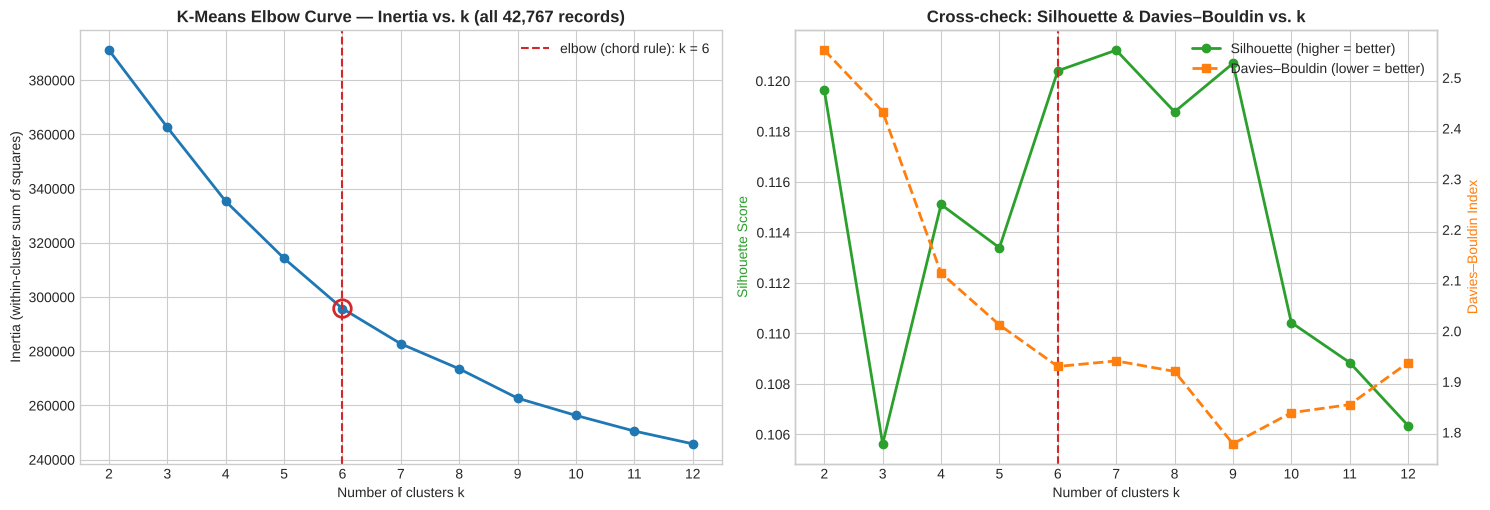

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
ax.plot(ks, sweep_df['Inertia'], 'o-', color=PALETTE[0], lw=2)
ax.axvline(k_knee, color=PALETTE[3], ls='--', lw=1.5, label=f'elbow (chord rule): k = {k_knee}')
ax.scatter([k_knee], [sweep_df.loc[k_knee, 'Inertia']], s=160, facecolor='none', edgecolor=PALETTE[3], lw=2, zorder=5)
ax.set_title(f'K-Means Elbow Curve — Inertia vs. k (all {len(X):,} records)', fontweight='bold'); ax.set_xlabel('Number of clusters k'); ax.set_ylabel('Inertia (within-cluster sum of squares)')
ax.set_xticks(ks); ax.legend()
ax = axes[1]
ax.plot(ks, sweep_df['Silhouette (10k sub)'], 'o-', color=PALETTE[2], lw=2, label='Silhouette (higher = better)')
ax.set_xlabel('Number of clusters k'); ax.set_ylabel('Silhouette Score', color=PALETTE[2]); ax.set_xticks(ks)
ax2 = ax.twinx(); ax2.plot(ks, sweep_df['Davies-Bouldin'], 's--', color=PALETTE[1], lw=2, label='Davies–Bouldin (lower = better)')
ax2.set_ylabel('Davies–Bouldin Index', color=PALETTE[1]); ax2.grid(False)
ax.axvline(k_knee, color=PALETTE[3], ls='--', lw=1.5)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc='upper right')
ax.set_title('Cross-check: Silhouette & Davies–Bouldin vs. k', fontweight='bold')
plt.tight_layout(); plt.show()

**Reading the Elbow curve.** Inertia falls smoothly from k = 2 to k = 12 — there is no sharp "elbow", which is typical of data without well-separated clusters. The chord rule (stated before looking at the result) locates the bend at **k = 6**, where the marginal gain per extra cluster visibly flattens. The cross-check supports it without being used to choose it: the Silhouette at k = 6 is 0.1204, within 0.001 of its maximum (0.1212 at k = 7), and Davies–Bouldin has dropped from 2.55 (k = 2) to 1.93. All Silhouette values lie in a narrow 0.106–0.121 band, i.e. **no k gives strongly separated clusters**.

In [9]:
K = int(k_knee)                                           # final k = elbow chosen by the stated rule
km_final = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
lab_km = km_final.labels_
print(f'Final K-Means: k={K}, inertia={km_final.inertia_:,.1f}, iterations={km_final.n_iter_}')
display(size_table(lab_km).T)

# Metrics: (a) full data (exact), (b) on the shared 8,000-record subset
t0 = time.time(); m_km_full = internal_metrics(X, lab_km); t_sil = time.time() - t0
m_km_sub = internal_metrics(X_s, lab_km[idx_sample])
print(f'K-Means on all {len(X):,} records :', {k: round(v, 4) for k, v in m_km_full.items()}, f'(exact silhouette took {t_sil:.0f}s)')
print(f'K-Means on the {N_SAMPLE:,}-record subset :', {k: round(v, 4) for k, v in m_km_sub.items()})

# Stability: same data, 5 different random initialisations -> do we get the same partition? (adjusted Rand index)
seeds = [1, 2, 3, 4, 5]
ref_lab = km_final.labels_
stab = [adjusted_rand_score(ref_lab, KMeans(n_clusters=K, n_init=1, random_state=s).fit(X).labels_) for s in seeds]
print('Stability — ARI of single-init K-Means (seeds 1-5) vs. final model:', np.round(stab, 3))

Final K-Means: k=6, inertia=295,737.4, iterations=18


,0,1,2,3,4,5
size,1432.00,8452.00,10122.00,3957.00,9789.00,9015.00
share_%,3.35,19.76,23.67,9.25,22.89,21.08


K-Means on all 42,767 records : {'Silhouette': 0.1195, 'Davies-Bouldin': 1.9289, 'Calinski-Harabasz': 4344.9738} (exact silhouette took 21s)
K-Means on the 8,000-record subset : {'Silhouette': 0.1202, 'Davies-Bouldin': 1.9183, 'Calinski-Harabasz': 835.8737}


Stability — ARI of single-init K-Means (seeds 1-5) vs. final model: [0.535 0.636 0.635 0.5   0.988]


In [10]:
# Cluster profiles in ORIGINAL (un-scaled) units — descriptive statistics of each K-Means cluster
prof_cols = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Is_Night'] + bool_keep
prof = feat[prof_cols].copy(); prof['Hour'] = t.dt.hour; prof['Month'] = t.dt.month; prof['Weekend'] = (t.dt.dayofweek >= 5).astype(float)
prof['cluster'] = lab_km
profile_km = prof.groupby('cluster').mean().round(3)
profile_km.insert(0, 'n', prof['cluster'].value_counts().sort_index())
profile_km.T

cluster,0,1,2,3,4,5
n,1432.000,8452.000,10122.000,3957.000,9789.000,9015.000
Start_Lat,39.234,37.337,40.034,38.161,36.178,30.911
Start_Lng,-112.421,-119.146,-81.890,-92.216,-101.117,-85.526
Temperature(F),53.927,56.075,44.923,48.940,77.321,72.177
Humidity(%),48.859,69.355,68.807,92.391,39.536,76.283
Pressure(in),25.635,29.833,29.815,29.711,29.698,29.908
Visibility(mi),9.668,9.487,9.879,2.908,10.078,9.651
Wind_Speed(mph),7.660,5.078,8.379,7.671,9.724,7.678
Is_Night,0.342,0.502,0.423,0.385,0.069,0.317
Traffic_Signal,0.166,0.084,0.148,0.123,0.178,0.226


## 7. Algorithm 2 — Agglomerative Hierarchical Clustering
Agglomerative clustering starts with every record as its own cluster and repeatedly merges the two *closest* clusters. "Closest" depends on the **linkage**:
* **Ward** — merge the pair that increases total within-cluster variance least (compact, similar-sized, K-Means-like clusters);
* **Complete** — distance between the *farthest* members; **Average** — mean pairwise distance; **Single** — distance between the *nearest* members (prone to "chaining").

All of it runs on the **8,000-record sample** (Section 5). Step 1 compares the four linkages at the same *k* as K-Means; step 2 draws the dendrogram of the chosen linkage; step 3 picks the number of clusters from the dendrogram.

In [11]:
# Step 1 — compare linkage strategies on the 8,000-record sample, at the K-Means k for a like-for-like comparison
link_rows, link_labels = [], {}
for lk in ['ward', 'complete', 'average', 'single']:
    t0 = time.time()
    ag = AgglomerativeClustering(n_clusters=K, linkage=lk).fit(X_s)
    lab = ag.labels_; link_labels[lk] = lab
    sz = np.bincount(lab)
    link_rows.append({'Linkage': lk, **{k: v for k, v in internal_metrics(X_s, lab).items()},
                      'Largest cluster %': 100 * sz.max() / sz.sum(), 'Smallest cluster %': 100 * sz.min() / sz.sum(), 'fit_s': time.time() - t0})
linkage_df = pd.DataFrame(link_rows).set_index('Linkage')
print(f'Linkage comparison at k={K} on the {N_SAMPLE:,}-record sample (Euclidean distance)')
linkage_df.round(4)

Linkage comparison at k=6 on the 8,000-record sample (Euclidean distance)


,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest cluster %,Smallest cluster %,fit_s
Linkage,,,,,,
ward,0.0797,2.3037,661.5907,29.4750,4.1500,3.1196
complete,0.2362,1.5022,226.3828,94.9250,0.0375,3.0074
average,0.3514,0.9452,67.9357,99.5125,0.0250,3.5455
single,0.4684,0.6699,53.7840,99.7750,0.0125,1.7822


**Linkage comparison — a metric trap.** At the same k = 6, single, average and complete linkage report a *much higher* Silhouette than Ward (single 0.468, average 0.351, complete 0.236 vs Ward 0.080) — but only because they are degenerate: the largest cluster holds 94.9 % / 99.5 % / 99.8 % of the points and the others are a handful of outliers (chaining). A high Silhouette earned by isolating a few outliers is not a useful segmentation. **Ward** is chosen because it minimises within-cluster variance (the same objective as K-Means) and yields balanced clusters (smallest = 4.2 %).

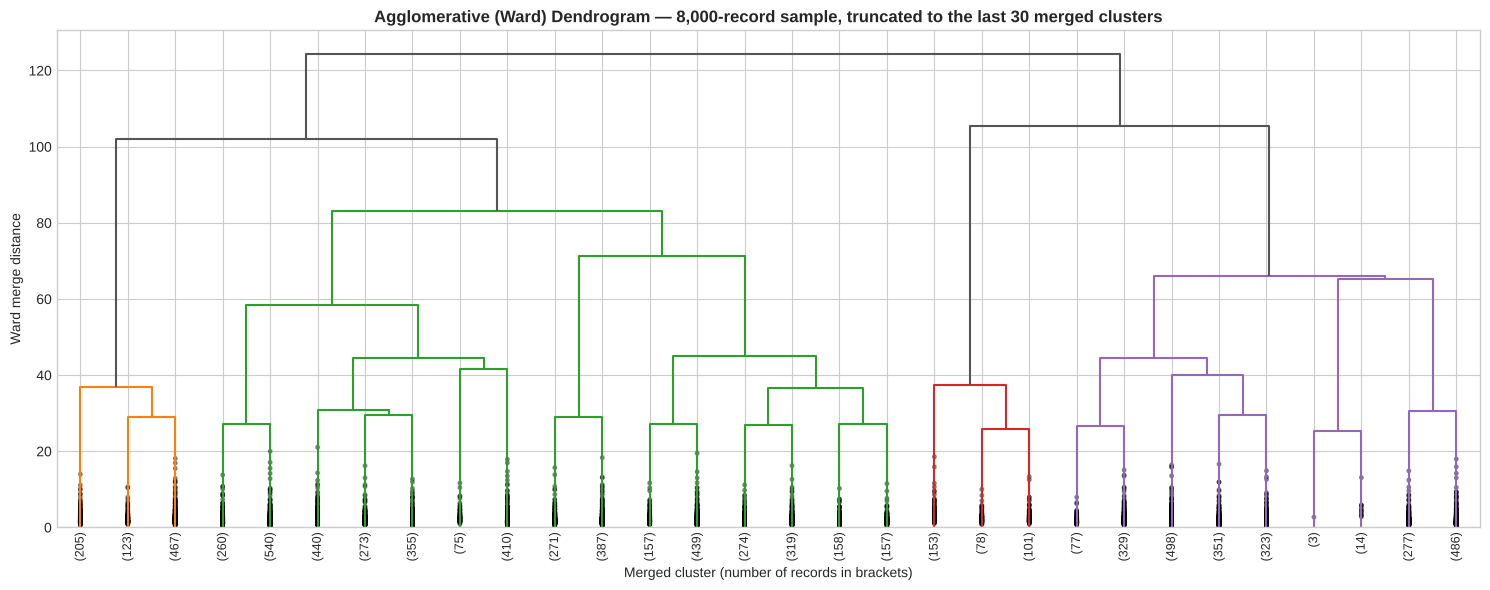

In [12]:
# Step 2 — dendrogram of the Ward linkage (SciPy), truncated to the last 30 merges so it stays readable
Z = linkage(X_s, method='ward')
fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, ax=ax, color_threshold=None, above_threshold_color='#555555')
ax.set_title(f'Agglomerative (Ward) Dendrogram — {N_SAMPLE:,}-record sample, truncated to the last 30 merged clusters', fontweight='bold')
ax.set_xlabel('Merged cluster (number of records in brackets)'); ax.set_ylabel('Ward merge distance')
plt.tight_layout(); plt.show()

In [13]:
# Step 3 — choose the number of clusters from the dendrogram: biggest jump in merge height among the final merges
heights = Z[:, 2]
cand_k = np.arange(2, 11)                                          # cutting into k clusters = undoing the last k-1 merges
gap = {int(k): float(heights[-(k - 1)] - heights[-k]) for k in cand_k}   # height needed to merge k clusters into k-1
# silhouette of Ward cuts, for the cross-check
ward_scan = []
for k in cand_k:
    lab = fcluster(Z, t=int(k), criterion='maxclust') - 1
    ward_scan.append({'k': int(k), 'merge-height gap before this cut': gap[int(k)], 'Silhouette': silhouette_score(X_s, lab),
                      'Davies-Bouldin': davies_bouldin_score(X_s, lab), 'Calinski-Harabasz': calinski_harabasz_score(X_s, lab)})
ward_scan = pd.DataFrame(ward_scan).set_index('k')
display(ward_scan.round(4))
K_AGG = int(ward_scan.loc[3:, 'merge-height gap before this cut'].idxmax())
print('Rule: largest merge-height gap among cuts with k >= 3 (k = 2 is excluded as the trivial split)  ->  k_agg =', K_AGG)

,merge-height gap before this cut,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,18.9987,0.1114,2.8445,813.4224
3,3.1685,0.1026,2.2803,753.4958
4,18.9198,0.1157,2.1792,755.6482
5,11.8398,0.0931,2.4197,710.5212
6,5.4331,0.0797,2.3037,661.5907
7,0.7987,0.0758,2.2971,623.0612
8,6.7326,0.0713,2.0775,598.7418
9,13.2702,0.0679,2.1215,572.6578
10,0.5590,0.0596,2.2515,536.2319


Rule: largest merge-height gap among cuts with k >= 3 (k = 2 is excluded as the trivial split)  ->  k_agg = 4


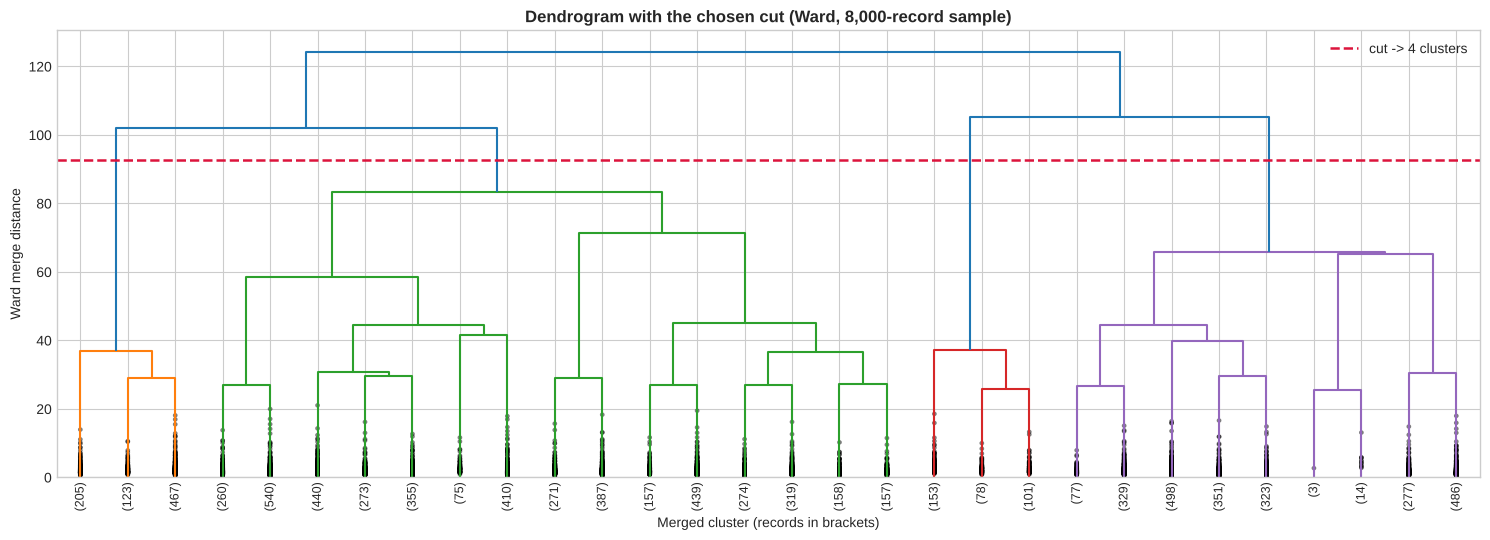

In [14]:
# Draw the cut on the full dendrogram's top part so the reader can see where k_agg comes from
fig, ax = plt.subplots(figsize=(15, 5.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, ax=ax, color_threshold=heights[-(K_AGG - 1)] - 1e-9)
cut_h = (heights[-(K_AGG - 1)] + heights[-K_AGG]) / 2
ax.axhline(cut_h, color='crimson', ls='--', lw=1.8, label=f'cut -> {K_AGG} clusters')
ax.set_title(f'Dendrogram with the chosen cut (Ward, {N_SAMPLE:,}-record sample)', fontweight='bold'); ax.set_xlabel('Merged cluster (records in brackets)'); ax.set_ylabel('Ward merge distance'); ax.legend()
plt.tight_layout(); plt.show()

In [15]:
# Fit the final hierarchical model with scikit-learn and verify it agrees with the SciPy cut
agg = AgglomerativeClustering(n_clusters=K_AGG, linkage='ward').fit(X_s)
lab_agg = agg.labels_
print('sklearn Ward labels vs SciPy fcluster labels, ARI =', round(adjusted_rand_score(lab_agg, fcluster(Z, t=K_AGG, criterion='maxclust')), 6), '(1.0 = identical partition)')
print(f'Final Agglomerative (Ward): k={K_AGG}, fitted on the {N_SAMPLE:,}-record sample')
display(size_table(lab_agg).T)
m_agg = internal_metrics(X_s, lab_agg)
print({k: round(v, 4) for k, v in m_agg.items()})

# Profiles in original units (sample records only)
profA = prof.iloc[idx_sample].drop(columns='cluster').copy(); profA['cluster'] = lab_agg
profile_agg = profA.groupby('cluster').mean().round(3); profile_agg.insert(0, 'n', profA['cluster'].value_counts().sort_index())
profile_agg.T

sklearn Ward labels vs SciPy fcluster labels, ARI = 1.0 (1.0 = identical partition)
Final Agglomerative (Ward): k=4, fitted on the 8,000-record sample


,0,1,2,3
size,4515.00,2358.00,332.00,795.00
share_%,56.44,29.48,4.15,9.94


{'Silhouette': 0.1157, 'Davies-Bouldin': 2.1792, 'Calinski-Harabasz': 755.6482}


cluster,0,1,2,3
n,4515.000,2358.000,332.000,795.000
Start_Lat,35.976,36.874,38.823,37.350
Start_Lng,-84.343,-118.559,-112.305,-93.118
Temperature(F),61.432,64.322,56.296,51.906
Humidity(%),66.270,56.271,47.251,91.657
Pressure(in),29.833,29.795,25.947,29.757
Visibility(mi),9.755,9.910,9.392,3.142
Wind_Speed(mph),8.556,6.848,7.200,7.153
Is_Night,0.304,0.336,0.292,0.389
Traffic_Signal,0.186,0.101,0.169,0.156


## 8. Like-for-Like Comparison on the Identical 8,000-Record Subset
The two algorithms may have chosen different *k*. Internal indices depend on *k* (Silhouette and Davies–Bouldin tend to prefer small *k*; Calinski–Harabasz tends to grow with *k*), so to isolate the **algorithm** from the **choice of k** we also fit K-Means with `k = k_agg` on the same subset (and Agglomerative with `k = K`), giving a matched-k comparison.

In [16]:
rows = []
def add(algo, k, fit_on, eval_on, m):
    rows.append({'Algorithm': algo, 'k': k, 'Fitted on': fit_on, 'Evaluated on': eval_on, **m})

add('K-Means', K, f'all {len(X):,}', f'all {len(X):,}', m_km_full)
add('K-Means', K, f'all {len(X):,}', f'{N_SAMPLE:,} subset', m_km_sub)
add('Agglomerative (Ward)', K_AGG, f'{N_SAMPLE:,} subset', f'{N_SAMPLE:,} subset', m_agg)
# matched-k controls on the identical subset
km_sub_kagg = KMeans(n_clusters=K_AGG, n_init=20, random_state=SEED).fit(X_s)
agg_K = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X_s)
if K_AGG != K:
    add('K-Means (control, matched k)', K_AGG, f'{N_SAMPLE:,} subset', f'{N_SAMPLE:,} subset', internal_metrics(X_s, km_sub_kagg.labels_))
    add('Agglomerative (control, matched k)', K, f'{N_SAMPLE:,} subset', f'{N_SAMPLE:,} subset', internal_metrics(X_s, agg_K.labels_))
else:
    add('K-Means (fitted on subset)', K, f'{N_SAMPLE:,} subset', f'{N_SAMPLE:,} subset', internal_metrics(X_s, km_sub_kagg.labels_))
comparison = pd.DataFrame(rows)
print('=== CLUSTERING COMPARISON TABLE — internal validity indices ===')
(comparison.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}'}).hide(axis='index')
 .set_caption('Silhouette ↑ higher better | Davies–Bouldin ↓ lower better | Calinski–Harabasz ↑ higher better'))

=== CLUSTERING COMPARISON TABLE — internal validity indices ===


Algorithm,k,Fitted on,Evaluated on,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,6,"all 42,767","all 42,767",0.1195,1.9289,"4,345.0"
K-Means,6,"all 42,767","8,000 subset",0.1202,1.9183,835.9
Agglomerative (Ward),4,"8,000 subset","8,000 subset",0.1157,2.1792,755.6
"K-Means (control, matched k)",4,"8,000 subset","8,000 subset",0.1156,2.0979,911.0
"Agglomerative (control, matched k)",6,"8,000 subset","8,000 subset",0.0797,2.3037,661.6


**How to read the three indices (their magnitudes are *not* comparable with each other):**
* **Silhouette Score** ∈ [−1, 1] — for each record, how much closer it is to its own cluster than to the nearest other cluster. **Higher is better**; ≈ 0 means overlapping clusters, < 0 means likely mis-assignment.
* **Davies–Bouldin Index** ≥ 0 — average, over clusters, of the worst ratio (within-cluster scatter) / (distance between cluster centres). **Lower is better**; 0 is the ideal.
* **Calinski–Harabasz Index** > 0 — ratio of between-cluster to within-cluster dispersion, scaled by degrees of freedom. **Higher is better**; it is unbounded, grows with *n* and with *k*, and so can only be compared between models with the same data and similar *k*.

The three can disagree. We compare each index only against the same index of another model on the same records, never across indices.

## 9. Cluster Visualisation — PCA (2 Components)
PCA is fitted on the **full** scaled matrix (42,768 records, labels not involved); the same two axes are used for both algorithms so the plots are directly comparable. The 8,000-record subset is plotted (the Agglomerative model only exists for those records).

PC1 explains 18.7%, PC2 explains 13.3% of the variance (total 32.0%) — the 2-D view is a lossy summary of a 20-D space.


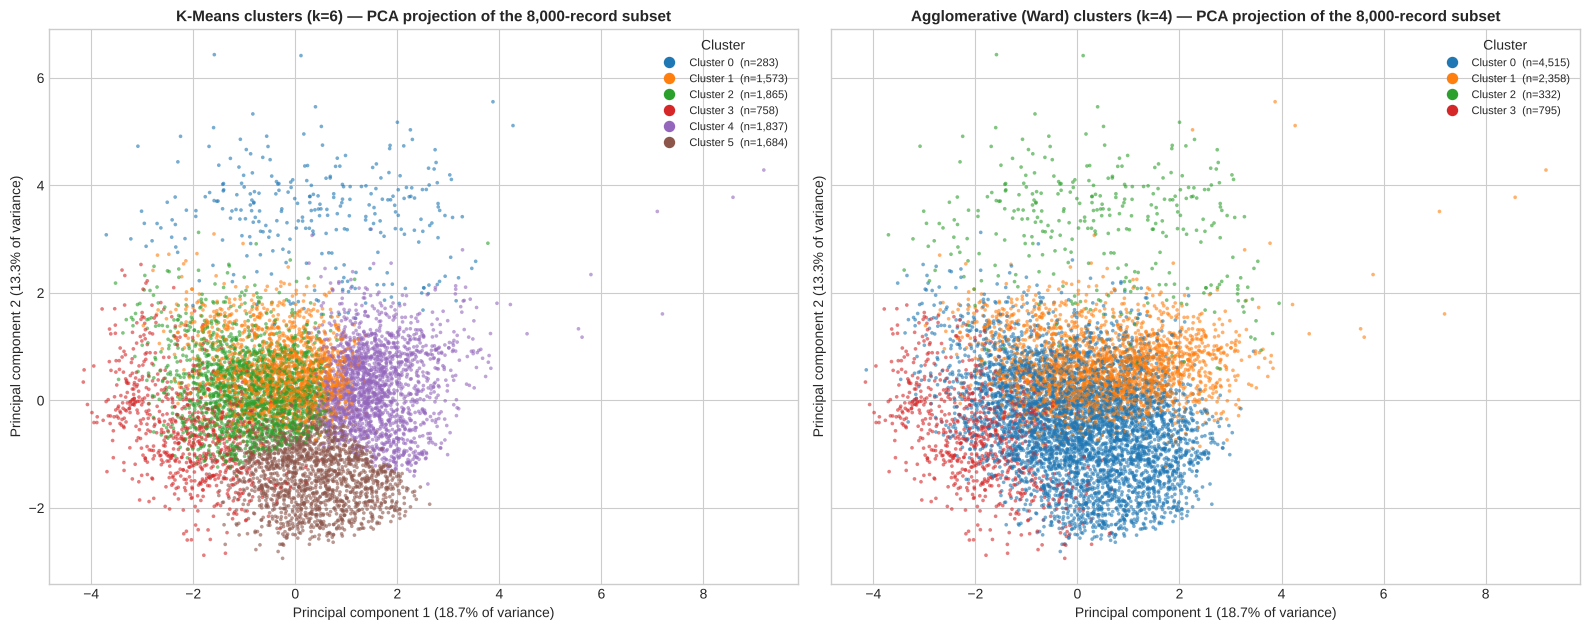

In [17]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
Z2 = pca.transform(X_s)
ev = pca.explained_variance_ratio_
print(f'PC1 explains {ev[0]:.1%}, PC2 explains {ev[1]:.1%} of the variance (total {ev.sum():.1%}) — the 2-D view is a lossy summary of a {X.shape[1]}-D space.')
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), sharex=True, sharey=True)
for ax, labs, name, kk in [(axes[0], lab_km[idx_sample], 'K-Means', K), (axes[1], lab_agg, 'Agglomerative (Ward)', K_AGG)]:
    sc = ax.scatter(Z2[:, 0], Z2[:, 1], c=labs, cmap='tab10', vmin=0, vmax=9, s=7, alpha=0.6, linewidths=0)
    ax.set_title(f'{name} clusters (k={kk}) — PCA projection of the {N_SAMPLE:,}-record subset', fontweight='bold', fontsize=11)
    ax.set_xlabel(f'Principal component 1 ({ev[0]:.1%} of variance)'); ax.set_ylabel(f'Principal component 2 ({ev[1]:.1%} of variance)')
    handles = [plt.Line2D([], [], marker='o', ls='', color=PALETTE[c], label=f'Cluster {c}  (n={int((labs == c).sum()):,})') for c in range(kk)]
    ax.legend(handles=handles, title='Cluster', loc='best', fontsize=8, markerscale=1.2)
plt.tight_layout(); plt.show()

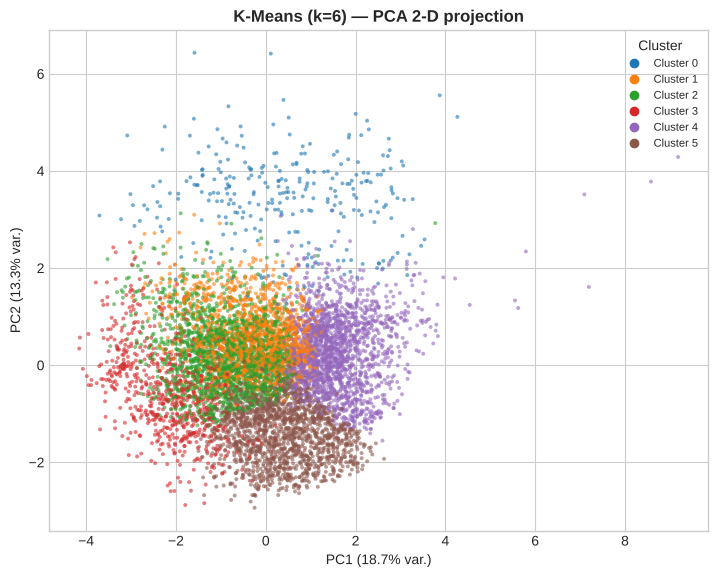

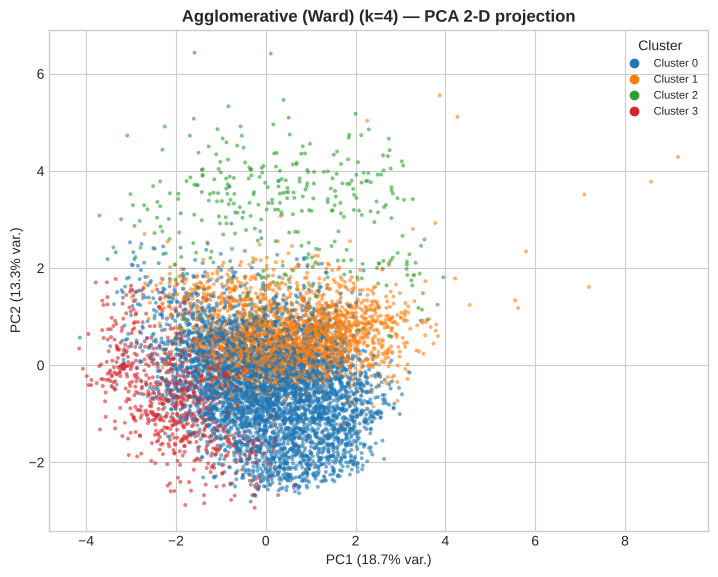

In [18]:
# Separate, individually titled full-size plots (one per algorithm) — also saved as PNG for the slides
os.makedirs('../results/figures', exist_ok=True)
for labs, name, kk, fn in [(lab_km[idx_sample], 'K-Means', K, 'pca_kmeans'), (lab_agg, 'Agglomerative (Ward)', K_AGG, 'pca_agglomerative')]:
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    ax.scatter(Z2[:, 0], Z2[:, 1], c=labs, cmap='tab10', vmin=0, vmax=9, s=8, alpha=0.6, linewidths=0)
    ax.set_title(f'{name} (k={kk}) — PCA 2-D projection', fontweight='bold'); ax.set_xlabel(f'PC1 ({ev[0]:.1%} var.)'); ax.set_ylabel(f'PC2 ({ev[1]:.1%} var.)')
    ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=PALETTE[c], label=f'Cluster {c}') for c in range(kk)], title='Cluster', fontsize=8)
    fig.savefig(f'../results/figures/{fn}.png', dpi=150, bbox_inches='tight'); plt.show()

## 10. Cluster Visualisation — t-SNE (encouraged)
t-SNE preserves **local** neighbourhoods and ignores global distances, so cluster *sizes and gaps in the picture are not meaningful*; it is used here only to see whether each algorithm's clusters form locally coherent groups. `perplexity=30`, `init='pca'`, `random_state=42`, on the 5,000-record subset of the sample. One embedding is coloured by both algorithms.

t-SNE finished in 24s; KL divergence = 1.950


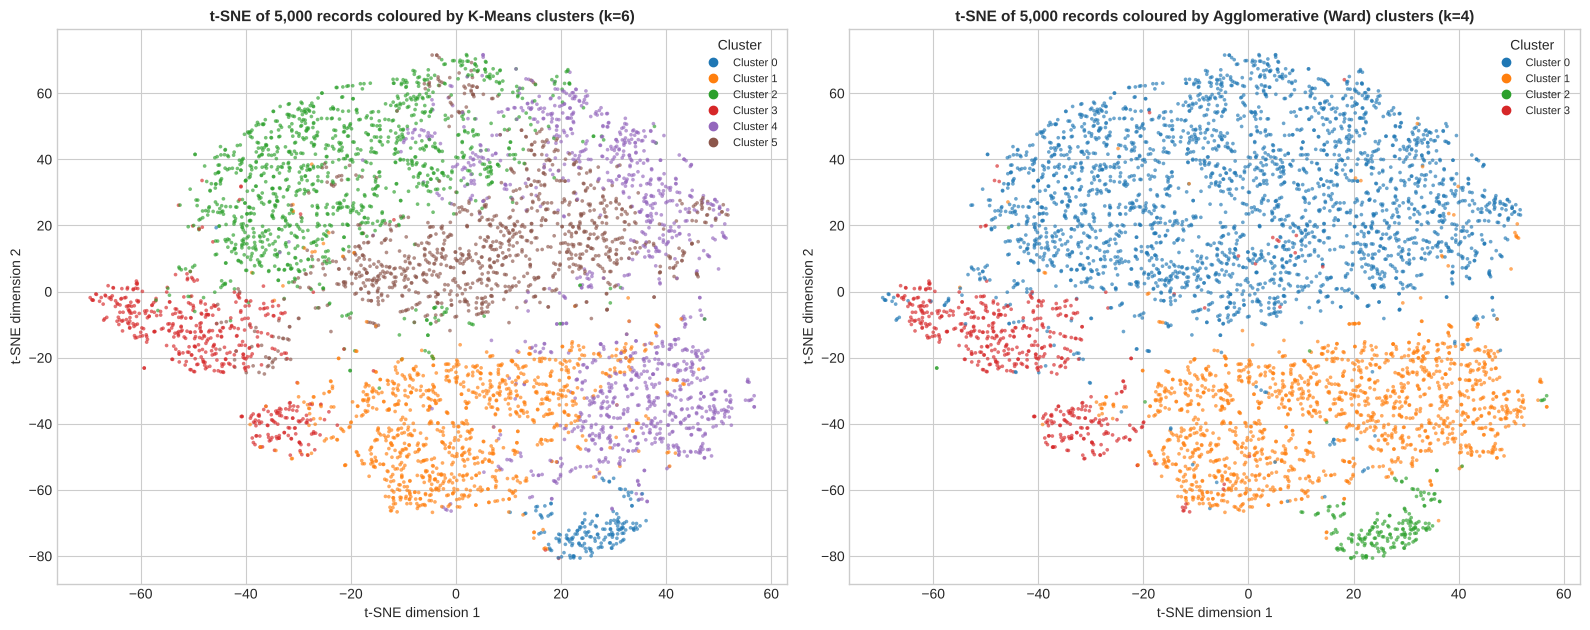

In [19]:
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED, max_iter=1000)
E = tsne.fit_transform(X[idx_tsne])
print(f't-SNE finished in {time.time()-t0:.0f}s; KL divergence = {tsne.kl_divergence_:.3f}')
pos = {r: i for i, r in enumerate(idx_sample)}
lab_agg_tsne = lab_agg[[pos[r] for r in idx_tsne]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
for ax, labs, name, kk in [(axes[0], lab_km[idx_tsne], 'K-Means', K), (axes[1], lab_agg_tsne, 'Agglomerative (Ward)', K_AGG)]:
    ax.scatter(E[:, 0], E[:, 1], c=labs, cmap='tab10', vmin=0, vmax=9, s=7, alpha=0.65, linewidths=0)
    ax.set_title(f't-SNE of {N_TSNE:,} records coloured by {name} clusters (k={kk})', fontweight='bold', fontsize=11)
    ax.set_xlabel('t-SNE dimension 1'); ax.set_ylabel('t-SNE dimension 2')
    ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=PALETTE[c], label=f'Cluster {c}') for c in range(kk)], title='Cluster', fontsize=8, loc='best')
plt.tight_layout()
fig.savefig('../results/figures/tsne_both.png', dpi=150, bbox_inches='tight'); plt.show()

## 11. External, Post-Hoc Interpretation (labels used *only now*, never for fitting)
Everything above was computed without `Severity` or `Distance(mi)`. Here — **after** the models are fixed — we look at how those outcomes distribute across the discovered clusters. This is *interpretation*, not a clustering metric: the clustering was never asked to separate severities, so a weak relationship is an honest finding and not a failure of the algorithm.

In [20]:
ref_k = ref.copy(); ref_k['cluster'] = lab_km
sev_ct = pd.crosstab(ref_k['cluster'], ref_k['Severity'], normalize='index').mul(100).round(1)
sev_ct.columns = [f'Sev {c} %' for c in sev_ct.columns]
ext = sev_ct.join(ref_k.groupby('cluster')['Distance(mi)'].agg(['mean', 'median']).round(3).rename(columns={'mean': 'Distance mean (mi)', 'median': 'Distance median (mi)'}))
ext.insert(0, 'n', ref_k['cluster'].value_counts().sort_index())
print('K-Means clusters (all records) vs. the outcome variables — post-hoc'); display(ext)

ari_k = adjusted_rand_score(ref['Severity'], lab_km); nmi_k = normalized_mutual_info_score(ref['Severity'], lab_km)
ref_s = ref.iloc[idx_sample]
ari_a = adjusted_rand_score(ref_s['Severity'], lab_agg); nmi_a = normalized_mutual_info_score(ref_s['Severity'], lab_agg)
ari_a_km = adjusted_rand_score(lab_km[idx_sample], lab_agg)
ext_tbl = pd.DataFrame({'ARI vs Severity': [ari_k, ari_a], 'NMI vs Severity': [nmi_k, nmi_a]}, index=['K-Means (all records)', 'Agglomerative (8k subset)']).round(4)
display(ext_tbl)
print('Agreement between the two algorithms on the subset: ARI =', round(ari_a_km, 4), '(1 = same partition)')
print('Reference: majority-class share of Severity 2 =', round((ref["Severity"] == 2).mean() * 100, 1), '%')

K-Means clusters (all records) vs. the outcome variables — post-hoc


,n,Sev 1 %,Sev 2 %,Sev 3 %,Sev 4 %,Distance mean (mi),Distance median (mi)
cluster,,,,,,,
0,1432,3.8,77.5,14.9,3.8,0.696,0.00
1,8452,0.9,78.5,18.7,1.9,0.271,0.00
2,10122,0.4,70.1,23.2,6.3,0.534,0.01
3,3957,0.4,70.6,24.3,4.7,0.475,0.00
4,9789,1.8,70.2,24.2,3.8,0.313,0.00
5,9015,0.7,75.1,20.4,3.8,0.365,0.00


,ARI vs Severity,NMI vs Severity
K-Means (all records),-0.0002,0.0060
Agglomerative (8k subset),-0.0151,0.0079


Agreement between the two algorithms on the subset: ARI = 0.3339 (1 = same partition)
Reference: majority-class share of Severity 2 = 73.1 %


**What the clusters mean (our interpretation of the profile table, Section 6).** The six K-Means clusters are mainly *geo-climatic regimes*: (0) high-altitude Mountain West (pressure ≈ 25.6 inHg); (1) California / Pacific coast; (2) the cold Ohio-Valley / Mid-Atlantic corridor; (3) a humid, low-visibility central group (visibility ≈ 2.9 mi, humidity ≈ 92 %); (4) the warm, dry Southern Plains with daytime accidents (≈ 7 % at night, mean hour ≈ 14.7); (5) the humid Southeast.

**External check.** The adjusted Rand index between the clusters and `Severity` is -0.0002 (K-Means) and -0.0151 (Ward): essentially zero. The Severity-2 share is 70–78 % in every cluster. This is expected — the clustering was never asked to separate severity and the features describe circumstances, not outcomes — and it confirms that the groups are not an accidental proxy for the label.

In [21]:
# Persist the result tables for the README / slides
comparison.to_csv('../results/clustering_comparison.csv', index=False)
sweep_df.to_csv('../results/clustering_kmeans_sweep.csv'); linkage_df.to_csv('../results/clustering_linkage_comparison.csv')
ward_scan.to_csv('../results/clustering_ward_scan.csv'); profile_km.to_csv('../results/clustering_kmeans_profiles.csv'); ext.to_csv('../results/clustering_posthoc_external.csv')
json.dump({'k_kmeans': K, 'k_agglomerative': K_AGG, 'n_features': int(X.shape[1]), 'n_records': int(len(X)), 'n_sample': N_SAMPLE, 'n_tsne': N_TSNE,
           'pca_var': [float(v) for v in ev], 'ari_vs_severity': {'kmeans': float(ari_k), 'agglomerative': float(ari_a)}, 'kmeans_stability_ari': [float(s) for s in stab],
           'features': feature_names, 'sklearn': sklearn.__version__}, open('../results/clustering_meta.json', 'w'), indent=2)
print('Saved results/*.csv|json and results/figures/*.png')

Saved results/*.csv|json and results/figures/*.png


## 12. Conclusions & Limitations
* **Both required algorithms were fitted and evaluated with all three metrics:** K-Means (k = 6, all 42,767 records) and Agglomerative/Ward (k = 4, 8,000-record random sample). Elbow curve, dendrogram, PCA plots for both algorithms and a t-SNE plot are above.
* **Structure is weak.** Silhouette ≈ 0.12 and Davies–Bouldin ≈ 1.9–2.2 indicate overlapping clusters; the partitions are only moderately reproducible across initialisations (single-init ARI 0.50–0.99), which is why the final model uses `n_init=20`. The clusters are best read as soft regional/climatic segments, not crisp natural classes.
* **Fair comparison.** On identical 8,000 records at matched k, K-Means is as good or better than Ward on every index (Section 8). Full-data Calinski–Harabasz is *not* comparable with the 8,000-record values (it scales with n).
* **Limitations:** Ward evaluated on a sample (O(n²) memory); one truncated record removed; features are one reasonable choice, not the only one; t-SNE is qualitative; no train/test split exists in clustering, so preprocessing statistics come from the full matrix (no labels involved).
* **Possible extensions:** DBSCAN/HDBSCAN on coordinates only for hot-spot discovery; Gaussian mixtures for soft membership.